In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

def moving_average(a, n=500):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def get_eps_greedy_action(Q, state, epsilon, n_actions):
    if np.random.random() < epsilon:
        return np.random.randint(n_actions)
    else:
        return np.random.choice(np.flatnonzero(Q[state] == Q[state].max()))
ACTION_MAP = {0: '↓', 1: '↑', 2: '→', 3: '←', 4: 'P', 5: 'D'}

TD(0) - 10000 eps:   0%|          | 0/10000 [00:00<?, ?it/s]

TD(0) - 200000 eps:   0%|          | 0/200000 [00:00<?, ?it/s]

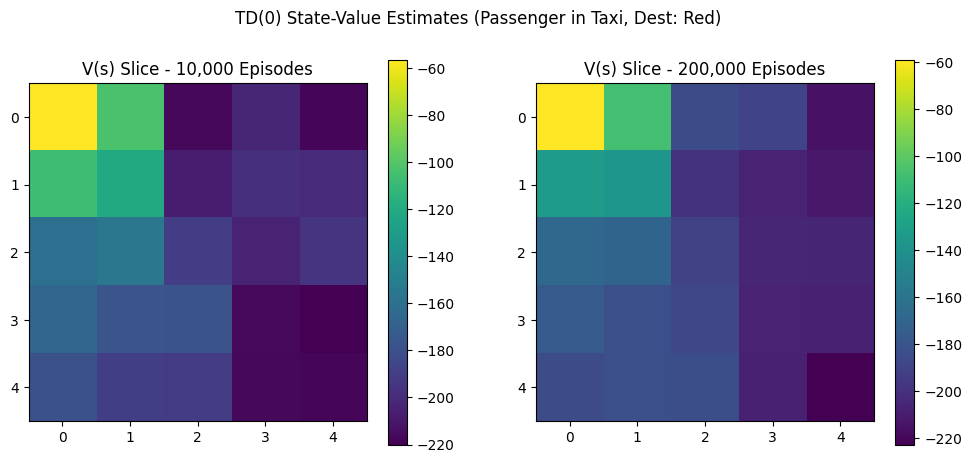

In [2]:
env = gym.make('Taxi-v3')

def td_0_prediction(episodes, alpha=0.1, gamma=0.99):
    V = np.zeros(env.observation_space.n)
    for _ in tqdm(range(episodes), desc=f"TD(0) - {episodes} eps"):
        state, _ = env.reset()
        done = False
        while not done:
            action = env.action_space.sample() 
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            td_target = reward + gamma * V[next_state] * (not done)
            V[state] += alpha * (td_target - V[state])
            state = next_state
    return V


V_10k = td_0_prediction(10000)
V_200k = td_0_prediction(200000)
slice_states = []
v_10k_grid = np.zeros((5, 5))
v_200k_grid = np.zeros((5, 5))

for row in range(5):
    for col in range(5):
        
        state = env.unwrapped.encode(row, col, 4, 0) 
        v_10k_grid[row, col] = V_10k[state]
        v_200k_grid[row, col] = V_200k[state]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
c1 = ax[0].imshow(v_10k_grid, cmap='viridis')
ax[0].set_title("V(s) Slice - 10,000 Episodes")
plt.colorbar(c1, ax=ax[0])

c2 = ax[1].imshow(v_200k_grid, cmap='viridis')
ax[1].set_title("V(s) Slice - 200,000 Episodes")
plt.colorbar(c2, ax=ax[1])

plt.suptitle("TD(0) State-Value Estimates (Passenger in Taxi, Dest: Red)")
plt.show()

SARSA:   0%|          | 0/50000 [00:00<?, ?it/s]

Q-Learning:   0%|          | 0/50000 [00:00<?, ?it/s]

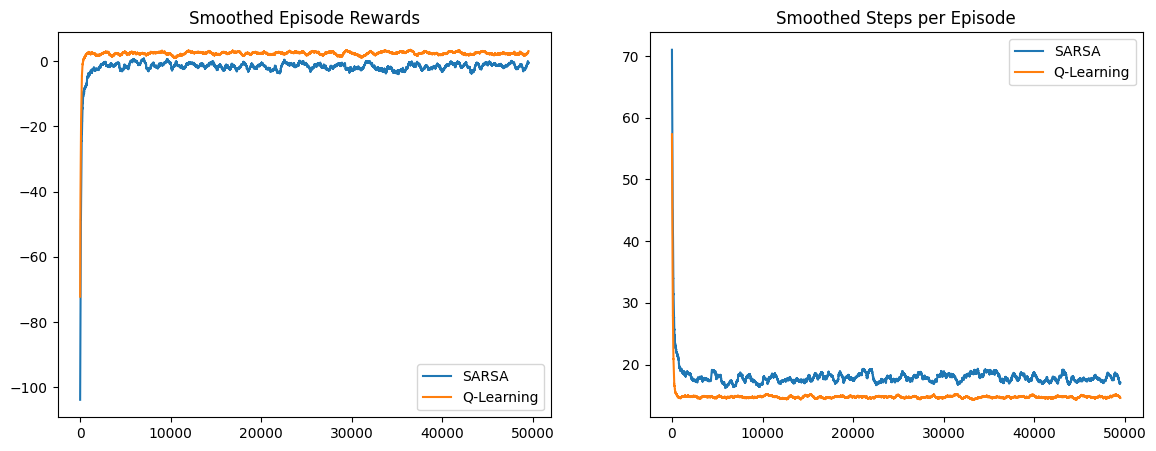


Q-Learning Greedy Policy (Passenger in taxi, Dest: Top-Left):
 [['D' '←' '↓' '↓' '↓']
 ['↑' '↑' '↓' '↓' '←']
 ['↑' '↑' '←' '←' '←']
 ['↑' '↑' '↑' '↑' '←']
 ['↑' '↑' '↑' '↑' '↑']]


In [3]:
def train_sarsa_q(episodes=50000, alpha=0.5, gamma=0.99, epsilon=0.1):
    Q_s = np.zeros((env.observation_space.n, env.action_space.n))
    Q_q = np.zeros((env.observation_space.n, env.action_space.n))
    rew_s, rew_q, step_s, step_q = np.zeros(episodes), np.zeros(episodes), np.zeros(episodes), np.zeros(episodes)
    
    for i in tqdm(range(episodes), desc="SARSA"):
        state, _ = env.reset()
        action = get_eps_greedy_action(Q_s, state, epsilon, 6)
        done, steps = False, 0
        while not done:
            next_state, reward, term, trunc, _ = env.step(action)
            done = term or trunc
            next_action = get_eps_greedy_action(Q_s, next_state, epsilon, 6)
            td_target = reward + gamma * Q_s[next_state, next_action] * (not done)
            Q_s[state, action] += alpha * (td_target - Q_s[state, action])
            state, action = next_state, next_action
            rew_s[i] += reward
            steps += 1
        step_s[i] = steps
        
    for i in tqdm(range(episodes), desc="Q-Learning"):
        state, _ = env.reset()
        done, steps = False, 0
        while not done:
            action = get_eps_greedy_action(Q_q, state, epsilon, 6)
            next_state, reward, term, trunc, _ = env.step(action)
            done = term or trunc
            best_next_a = np.argmax(Q_q[next_state])
            td_target = reward + gamma * Q_q[next_state, best_next_a] * (not done)
            Q_q[state, action] += alpha * (td_target - Q_q[state, action])
            state = next_state
            rew_q[i] += reward
            steps += 1
        step_q[i] = steps
        
    return Q_s, Q_q, rew_s, rew_q, step_s, step_q

Q_sarsa, Q_qlearn, r_sarsa, r_qlearn, s_sarsa, s_qlearn = train_sarsa_q()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(moving_average(r_sarsa), label="SARSA")
ax1.plot(moving_average(r_qlearn), label="Q-Learning")
ax1.set_title("Smoothed Episode Rewards"), ax1.legend()

ax2.plot(moving_average(s_sarsa), label="SARSA")
ax2.plot(moving_average(s_qlearn), label="Q-Learning")
ax2.set_title("Smoothed Steps per Episode"), ax2.legend()
plt.show()
policy_grid = np.empty((5, 5), dtype=str)
for r in range(5):
    for c in range(5):
        s = env.unwrapped.encode(r, c, 4, 0)
        best_a = np.argmax(Q_qlearn[s])
        policy_grid[r, c] = ACTION_MAP[best_a]
print("\nQ-Learning Greedy Policy (Passenger in taxi, Dest: Top-Left):\n", policy_grid)

Sweeping Alpha:   0%|          | 0/4 [00:00<?, ?it/s]

Sweeping Gamma:   0%|          | 0/4 [00:00<?, ?it/s]

Sweeping Epsilon:   0%|          | 0/4 [00:00<?, ?it/s]

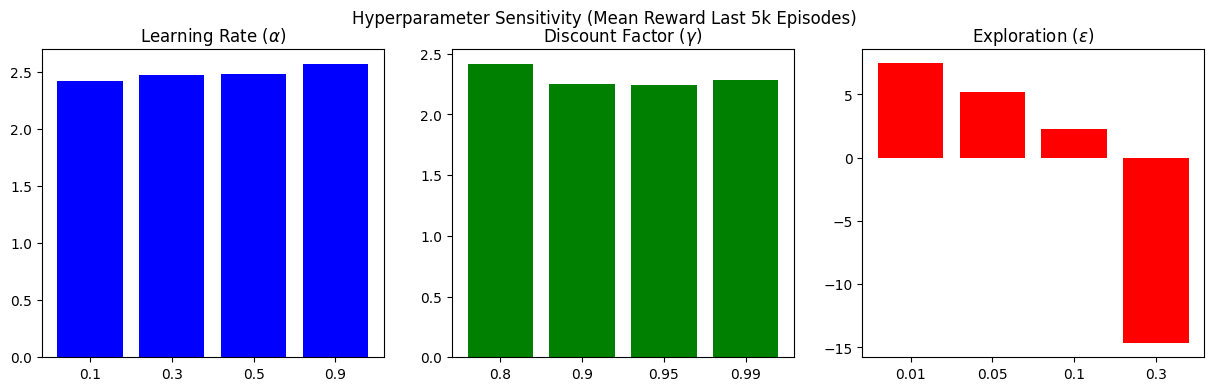

In [4]:
def run_q_learning_eval(alpha, gamma, epsilon, episodes=30000, eval_win=5000):
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    rewards = np.zeros(episodes)
    for i in range(episodes):
        state, _ = env.reset()
        done = False
        while not done:
            action = get_eps_greedy_action(Q, state, epsilon, 6)
            next_state, reward, term, trunc, _ = env.step(action)
            done = term or trunc
            td_target = reward + gamma * Q[next_state, np.argmax(Q[next_state])] * (not done)
            Q[state, action] += alpha * (td_target - Q[state, action])
            state = next_state
            rewards[i] += reward
    return np.mean(rewards[-eval_win:])

alphas = [0.1, 0.3, 0.5, 0.9]
gammas = [0.8, 0.9, 0.95, 0.99]
epsilons = [0.01, 0.05, 0.1, 0.3]

res_a = [run_q_learning_eval(a, 0.99, 0.1) for a in tqdm(alphas, desc="Sweeping Alpha")]
res_g = [run_q_learning_eval(0.5, g, 0.1) for g in tqdm(gammas, desc="Sweeping Gamma")]
res_e = [run_q_learning_eval(0.5, 0.99, e) for e in tqdm(epsilons, desc="Sweeping Epsilon")]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].bar([str(a) for a in alphas], res_a, color='b')
axs[0].set_title(r"Learning Rate ($\alpha$)")
axs[1].bar([str(g) for g in gammas], res_g, color='g')
axs[1].set_title(r"Discount Factor ($\gamma$)")
axs[2].bar([str(e) for e in epsilons], res_e, color='r')
axs[2].set_title(r"Exploration ($\varepsilon$)")
fig.suptitle("Hyperparameter Sensitivity (Mean Reward Last 5k Episodes)")
plt.show()

1-step SARSA:   0%|          | 0/50000 [00:00<?, ?it/s]

3-step SARSA:   0%|          | 0/50000 [00:00<?, ?it/s]

5-step SARSA:   0%|          | 0/50000 [00:00<?, ?it/s]

10-step SARSA:   0%|          | 0/50000 [00:00<?, ?it/s]

20-step SARSA:   0%|          | 0/50000 [00:00<?, ?it/s]

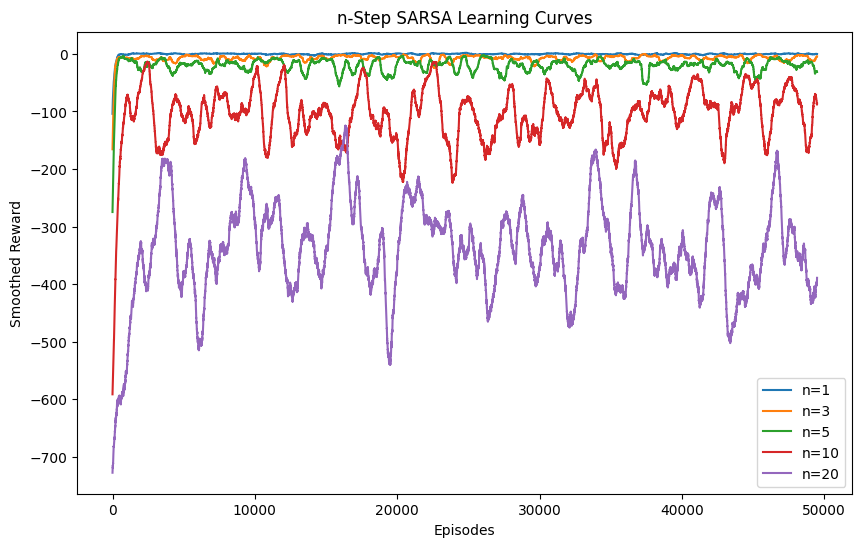

In [5]:
def n_step_sarsa(episodes, n, alpha=0.4, gamma=0.99, epsilon=0.1):
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    episode_rewards = np.zeros(episodes)
    
    for ep in tqdm(range(episodes), desc=f"{n}-step SARSA"):
        state, _ = env.reset()
        action = get_eps_greedy_action(Q, state, epsilon, 6)
        T, t = float('inf'), 0
        states, actions, rewards = [state], [action], [0.0]
        
        while True:
            if t < T:
                next_state, reward, term, trunc, _ = env.step(actions[t])
                done = term or trunc
                states.append(next_state)
                rewards.append(reward)
                episode_rewards[ep] += reward
                if done:
                    T = t + 1
                else:
                    next_a = get_eps_greedy_action(Q, next_state, epsilon, 6)
                    actions.append(next_a)
            
            tau = t - n + 1
            if tau >= 0:
                G = sum([gamma**(i - tau - 1) * rewards[i] for i in range(tau + 1, min(tau + n, T) + 1)])
                if tau + n < T:
                    G += gamma**n * Q[states[tau + n], actions[tau + n]]
                Q[states[tau], actions[tau]] += alpha * (G - Q[states[tau], actions[tau]])
            
            if tau == T - 1:
                break
            t += 1
    return episode_rewards

ns = [1, 3, 5, 10, 20]
plt.figure(figsize=(10, 6))
for n in ns:
    rewards = n_step_sarsa(50000, n)
    plt.plot(moving_average(rewards), label=f"n={n}")
plt.title("n-Step SARSA Learning Curves")
plt.xlabel("Episodes")
plt.ylabel("Smoothed Reward")
plt.legend()
plt.show()

Calculating V*:   0%|          | 0/50000 [00:00<?, ?it/s]

TD(λ=0.0):   0%|          | 0/100000 [00:00<?, ?it/s]

TD(λ=0.3):   0%|          | 0/100000 [00:00<?, ?it/s]

TD(λ=0.5):   0%|          | 0/100000 [00:00<?, ?it/s]

TD(λ=0.7):   0%|          | 0/100000 [00:00<?, ?it/s]

TD(λ=0.9):   0%|          | 0/100000 [00:00<?, ?it/s]

TD(λ=1.0):   0%|          | 0/100000 [00:00<?, ?it/s]

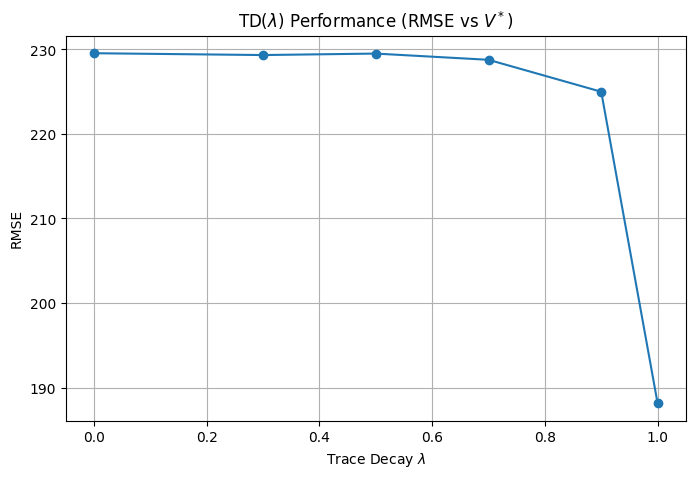

In [6]:
def get_v_star():
   
    Q, _ = run_q_learning_full(50000, 0.5, 0.99, 0.1) 
    return np.max(Q, axis=1)

def run_q_learning_full(episodes, alpha, gamma, epsilon):
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    for i in tqdm(range(episodes), desc="Calculating V*"):
        s, _ = env.reset()
        done = False
        while not done:
            a = get_eps_greedy_action(Q, s, epsilon, 6)
            next_s, r, term, trunc, _ = env.step(a)
            done = term or trunc
            Q[s, a] += alpha * (r + gamma * np.max(Q[next_s]) * (not done) - Q[s, a])
            s = next_s
    return Q, None

def td_lambda_prediction(true_v, lambd, episodes=100000, alpha=0.01, gamma=0.99):
    V = np.zeros(env.observation_space.n)
    for _ in tqdm(range(episodes), desc=f"TD(λ={lambd})"):
        state, _ = env.reset()
        E = np.zeros(env.observation_space.n)
        done = False
        while not done:
            action = env.action_space.sample()
            next_state, reward, term, trunc, _ = env.step(action)
            done = term or trunc
            
            delta = reward + gamma * V[next_state] * (not done) - V[state]
            E[state] += 1 
            
            V += alpha * delta * E
            E *= gamma * lambd
            state = next_state
    return np.sqrt(np.mean((V - true_v)**2))

V_star = get_v_star()
lambdas = [0.0, 0.3, 0.5, 0.7, 0.9, 1.0]
rmses = [td_lambda_prediction(V_star, l) for l in lambdas]

plt.figure(figsize=(8, 5))
plt.plot(lambdas, rmses, marker='o', linestyle='-')
plt.title(r"TD($\lambda$) Performance (RMSE vs $V^*$)")
plt.xlabel(r"Trace Decay $\lambda$")
plt.ylabel("RMSE")
plt.grid(True)
plt.show()